# TP final IA II - Paso 4: ¿mejora el modelo si además de la imagen le damos el clima?

El notebook 03 respondió la consigna: una red CNN + RNN que **solo mira imágenes**. Este notebook es una extensión: a la misma red se le agrega, para cada período de 10 días, **la lluvia y la temperatura** del lugar (ERA5-Land, bajado en el notebook 02). La pregunta es cuánto aporta el clima **además** de lo que ya se ve en la imagen.

**Por qué podría ayudar:** el rinde depende mucho de la lluvia y de los golpes de calor, sobre todo en momentos clave como la floración. Parte de eso se ve en la imagen (un cultivo seco tiene menos verde), pero no todo: un cultivo puede verse verde y llenar mal los granos por calor.

**Para que la comparación sea justa**, se usan **exactamente las mismas particiones** que el 03 (se leen de `particiones_03.csv`) y la misma red: lo único que cambia es la entrada de clima. Si el 03 todavía no se corrió, este notebook entrena también la red sin clima.

**Qué se compara:**

| Modelo | Qué ve |
|---|---|
| Referencia | Por departamento: el rinde medio del cultivo y la campaña reales. Dejando un año afuera: el promedio histórico del cultivo. |
| Clima + cultivo real (RF) | Random Forest que conoce el cultivo **real** y el clima, pero no la imagen. Mide cuánto del rinde explica el clima solo. |
| Random Forest / Random Forest + clima | Promedios de la imagen por período, sin y con clima. |
| CNN + LSTM / CNN + LSTM + clima | La red del 03, sin y con clima. |
| CNN + LSTM y Random Forest, **hasta enero** | Con datos solo hasta enero, dejando un año afuera: un **pronóstico antes de la cosecha** en una campaña que el modelo no vio. |

Igual que en el 03, se evalúa **por departamento** y **dejando un año afuera**. Esta última es la prueba clave: predecir el rinde de una campaña que el modelo nunca vio, que es donde el clima debería ayudar más.

**Antes de correrlo:** GPU (se usó una L4), el dataset del 02 versión 2 y el 03 versión 2 ya corrido. Se entrenaron 11 redes con clima (5 por departamento y 6 dejando un año afuera) y 6 redes "hasta enero" sin clima dejando un año afuera; retoma sola si se corta.

In [1]:
PRUEBA = False   # usar el mismo valor que en el 03

import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/TP_final_IA2'
except ImportError:
    BASE = os.environ.get('TP_BASE', 'TP_final_IA2')

DATASET  = f'{BASE}/dataset_v2'
R03      = f'{BASE}/resultados_03v2_prueba' if PRUEBA else f'{BASE}/resultados_03v2'
SALIDA   = f'{BASE}/resultados_04_prueba' if PRUEBA else f'{BASE}/resultados_04'
CORRIDAS = f'{SALIDA}/corridas'
os.makedirs(CORRIDAS, exist_ok=True)
for f in ['dataset_cultivos.npz', 'dataset_meta.csv']:
    assert os.path.exists(f'{DATASET}/{f}'), f'Falta {DATASET}/{f}: corré el notebook 02 versión 2'
print('Resultados en', SALIDA)

Mounted at /content/drive
Resultados en /content/drive/MyDrive/TP_final_IA2/resultados_04


In [2]:
import time, json, hashlib, inspect, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, regularizers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error
warnings.filterwarnings('ignore', message='.*shuffle=True.*')
tf.get_logger().setLevel('ERROR')

SEED = 42
keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow', tf.__version__, '| GPU:', gpus if gpus else 'NO HAY GPU: activá T4')
MIXTA = bool(gpus)
if MIXTA:
    keras.mixed_precision.set_global_policy('mixed_float16')

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Parámetros

Los hiperparámetros son los del 03, para que la única diferencia sea el clima.

In [3]:
CLASES     = ['Maíz', 'Soja 1ra', 'Soja 2da', 'Otros']
CULTIVOS   = [0, 1, 2]
BANDAS_S2  = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
CANALES    = BANDAS_S2 + ['NDVI', 'NDRE']
VARS_CLIMA = ['lluvia', 'tmedia', 'tmax']
T_FULL, PATCH, T_ENE = 27, 16, 15          # 15 períodos = de septiembre a enero
MESES = ['sep', 'oct', 'nov', 'dic', 'ene', 'feb', 'mar', 'abr', 'may']

N_FOLDS, EPOCAS, PACIENCIA = 5, (2 if PRUEBA else 60), 10
BATCH, LR, L2, DROPOUT = 64, 1e-3, 1e-4, 0.3
FILTROS, UNIDADES_RNN, PESO_RINDE = (16, 32, 64), 64, 0.5
N_PRUEBA, RF_ARBOLES, VERSION = 600, (100 if PRUEBA else 300), 1

EXPERIMENTOS = {
    'CNN + LSTM':                    dict(clima=False, periodos=T_FULL),
    'CNN + LSTM + clima':            dict(clima=True,  periodos=T_FULL),
    'CNN + LSTM, hasta ene':         dict(clima=False, periodos=T_ENE),
    'CNN + LSTM + clima, hasta ene': dict(clima=True,  periodos=T_ENE),
}
# Qué se entrena acá. Las redes sin clima se toman del 03 (se decide en la sección 3).
# Tiempos aproximados con GPU L4 (con T4, un 50 % más):
#   'CNN + LSTM + clima'             -> depto ~50 min, anio ~70 min
#   'CNN + LSTM + clima, hasta ene'  -> depto ~30 min, anio ~40 min
#   'CNN + LSTM, hasta ene' (anio)   -> ~40 min (el 03 no lo corrió en este esquema; hace falta para comparar el pronóstico temprano)
CORRER_DEPTO = ['CNN + LSTM + clima']
CORRER_ANIO  = ['CNN + LSTM + clima', 'CNN + LSTM, hasta ene']
# Versión completa (~4 h con L4):
# CORRER_DEPTO = ['CNN + LSTM + clima', 'CNN + LSTM + clima, hasta ene']
# CORRER_ANIO  = ['CNN + LSTM + clima', 'CNN + LSTM + clima, hasta ene', 'CNN + LSTM, hasta ene']
# Redes cuyo modelo entrenado se guarda en Drive (para servirlo en la página / API).
# Si el resultado ya está guardado pero falta su modelo, esa partición se vuelve a entrenar.
GUARDAR_MODELOS = ['CNN + LSTM, hasta ene']
ENTRENAR_MODELO_FINAL = False   # solo hacía falta para aplicar el modelo a un campo (notebook 05, que quedó afuera)
ESQUEMAS = {'depto': 'por departamento', 'anio': 'dejando un año afuera'}

## 2. Carga

Igual que en el 03 (misma muestra en modo prueba). El clima se transforma así:
- **Lluvia:** como es muy asimétrica (muchos períodos con poca lluvia y algunos con mucha), se usa `log(1 + mm)`.
- **Las tres variables** se estandarizan con la media y el desvío de train de cada partición.

In [4]:
d = np.load(f'{DATASET}/dataset_cultivos.npz')
assert 'clima' in d.files, 'El dataset no tiene clima: corré el notebook 02 versión 2'
X_u16, y_cultivo, ids, CL = d['X'], d['y_cultivo'].astype(np.int64), d['id'], d['clima'].astype(np.float32)
meta = pd.read_csv(f'{DATASET}/dataset_meta.csv')
assert meta.id.is_unique and len(meta) == len(ids)
meta = meta.set_index('id').loc[ids].reset_index()
assert (meta.clase.values == y_cultivo).all()
assert X_u16.shape[1:] == (T_FULL, PATCH, PATCH, len(BANDAS_S2)) and CL.shape[1:] == (T_FULL, len(VARS_CLIMA))

if PRUEBA:      # la misma muestra que el 03
    rng = np.random.default_rng(SEED)
    grupos_cc = meta.groupby(['campana', 'clase']).indices
    por = max(1, N_PRUEBA // len(grupos_cc))
    sel = np.sort(np.concatenate([rng.choice(v, size=min(por, len(v)), replace=False) for v in grupos_cc.values()]))
    X_u16, y_cultivo, ids, CL, meta = X_u16[sel], y_cultivo[sel], ids[sel], CL[sel], meta.iloc[sel].reset_index(drop=True)
N = len(meta)

ib = {b: i for i, b in enumerate(BANDAS_S2)}
X_all = np.empty((N, T_FULL, PATCH, PATCH, len(CANALES)), np.float16)
for i in range(0, N, 500):
    x = X_u16[i:i + 500].astype(np.float32) / 10000.0
    ndvi = (x[..., ib['B8']] - x[..., ib['B4']]) / np.maximum(x[..., ib['B8']] + x[..., ib['B4']], 1e-6)
    ndre = (x[..., ib['B8A']] - x[..., ib['B5']]) / np.maximum(x[..., ib['B8A']] + x[..., ib['B5']], 1e-6)
    X_all[i:i + 500] = np.concatenate([x, ndvi[..., None], ndre[..., None]], axis=-1)
del X_u16, d

S1 = np.zeros((N, len(CANALES))); S2 = np.zeros((N, len(CANALES)))
F_RF = np.zeros((N, T_FULL, len(CANALES)), np.float32)
for i in range(0, N, 500):
    x = X_all[i:i + 500].astype(np.float32)
    S1[i:i + 500] = x.mean(axis=(1, 2, 3)); S2[i:i + 500] = (x ** 2).mean(axis=(1, 2, 3))
    F_RF[i:i + 500] = x.mean(axis=(2, 3))

CL[..., 0] = np.log1p(np.maximum(CL[..., 0], 0))          # lluvia -> log(1 + mm)
assert np.isfinite(CL).all(), 'Hay valores de clima faltantes'
campanas = sorted(meta.campana.unique())

print('X:', X_all.shape, '| clima:', CL.shape)
lluvia = pd.DataFrame({'campaña': meta.campana, 'lluvia sep-may (mm)': np.expm1(CL[..., 0]).sum(axis=1),
                       'tmax media (°C)': CL[..., 2].mean(axis=1)})
print('\nClima medio por campaña:'); print(lluvia.groupby('campaña').mean().round(1).to_string())

X: (18692, 27, 16, 16, 12) | clima: (18692, 27, 3)

Clima medio por campaña:
         lluvia sep-may (mm)  tmax media (°C)
campaña                                      
2019_20           714.500000        26.100000
2020_21           697.599976        25.700001
2021_22           583.299988        25.799999
2022_23           484.500000        27.600000
2023_24           845.000000        25.100000
2024_25           728.299988        26.799999


## 3. Las mismas particiones que el 03

Se arman con el mismo código y la misma semilla que el 03, y se comparan contra `particiones_03.csv`. Si coinciden, **las predicciones sin clima se toman del 03** (no hace falta reentrenarlas). Si el 03 no está o las particiones no coinciden, la red sin clima se entrena acá.

In [5]:
estrato = y_cultivo + len(CLASES) * meta.campana.map({c: i for i, c in enumerate(campanas)}).values
grupos = meta.grupo.values

def particion_interna(tr, seed):
    sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    a, b = min(sg.split(tr, estrato[tr], grupos[tr]), key=lambda ab: abs(len(ab[1]) / len(tr) - 0.2))
    return np.sort(tr[a]), np.sort(tr[b])

FOLDS = {'depto': [], 'anio': []}
for k, (tr, te) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(N), estrato, grupos)):
    a, b = particion_interna(tr, SEED + k)
    FOLDS['depto'].append({'train': a, 'val': b, 'test': np.sort(te), 'nombre': f'partición {k}'})
for k, camp in enumerate(campanas):
    te, tr = np.flatnonzero(meta.campana.values == camp), np.flatnonzero(meta.campana.values != camp)
    a, b = particion_interna(tr, SEED + 100 + k)
    FOLDS['anio'].append({'train': a, 'val': b, 'test': te, 'nombre': camp})

USAR_03 = False
ruta_p = f'{R03}/particiones_03.csv'
if os.path.exists(ruta_p) and os.path.exists(f'{R03}/predicciones.csv'):
    p03 = pd.read_csv(ruta_p).set_index('id')
    if set(p03.index) == set(ids):
        p03 = p03.loc[ids]
        USAR_03 = all((p03[f'test_{esq}'].values[f['test']] == k).all() for esq in FOLDS for k, f in enumerate(FOLDS[esq]))
if USAR_03:
    print('Las particiones coinciden con las del 03: las redes sin clima se toman de sus predicciones.')
    DEL_03 = {'depto': ['CNN + LSTM', 'CNN + LSTM, hasta ene'], 'anio': ['CNN + LSTM']}
else:
    print('No se pudieron usar los resultados del 03 (no está corrido o sus particiones no coinciden): '
          'la red sin clima se entrena también acá.')
    DEL_03 = {'depto': [], 'anio': []}
    CORRER_DEPTO = ['CNN + LSTM', 'CNN + LSTM, hasta ene'] + CORRER_DEPTO
    CORRER_ANIO = ['CNN + LSTM'] + CORRER_ANIO

Las particiones coinciden con las del 03: las redes sin clima se toman de sus predicciones.


## 4. Baselines (se guardan y se reutilizan)

- **Media de train** y **Referencia**, como en el 03.
- **Random Forest** con los promedios de la imagen por período, **sin y con clima**, viendo hasta mayo y hasta enero.
- **Clima + cultivo real (RF):** un regresor que recibe el clima y el cultivo **verdadero** (sin imagen). Solo predice rinde.

Para que no tarden tanto (en el 03 los baselines tardaron más de una hora), cada árbol se entrena con la mitad de los parches (`max_samples=0.5`). La primera vez igual tardan un rato; después se cargan de Drive.

In [6]:
OBJ = 'rinde_sembrado'
PRED, FILAS = {}, []

def nuevo_pred():
    return {'pc': np.full(N, -1), 'pr': np.full(N, np.nan)}

def metricas(idx, pc, pr):
    out = {}
    if pc is not None:
        out['F1 macro'] = f1_score(y_cultivo[idx], pc, average='macro', labels=range(len(CLASES)), zero_division=0)
        out['F1 cultivos'] = f1_score(y_cultivo[idx], pc, average='macro', labels=CULTIVOS, zero_division=0)
    real = meta[OBJ].values[idx]
    ok = np.isfinite(real) & np.isfinite(pr)
    if ok.sum():
        out['MAE rinde (kg/ha)'] = mean_absolute_error(real[ok], pr[ok])
        df = meta.iloc[idx][['grupo', 'cultivo', 'campana']].assign(real=real, pred=pr)[ok]
        g = df.groupby(['grupo', 'cultivo', 'campana']).agg(real=('real', 'first'), pred=('pred', 'mean'))
        out['MAE por depto (kg/ha)'] = mean_absolute_error(g.real, g.pred)
    return out

def registrar(esq, nombre, k, idx, pc, pr, extra=None):
    p = PRED.setdefault((esq, nombre), nuevo_pred())
    if pc is not None:
        p['pc'][idx] = pc
    p['pr'][idx] = pr
    FILAS.append({'esquema': esq, 'modelo': nombre, 'fold': k, **metricas(idx, pc, pr), **(extra or {})})

def media_depto(idx_hist, idx_eval):
    # Rinde medio de ese cultivo en ese departamento en las otras campañas (igual que en el 03)
    h = meta.iloc[idx_hist]
    por_camp = h.groupby(['grupo', 'cultivo', 'campana'])[OBJ].first().dropna()
    m_gc = por_camp.groupby(['grupo', 'cultivo']).mean()
    m_c = por_camp.groupby('cultivo').mean()
    ev = meta.iloc[idx_eval]
    pr = pd.Series(list(zip(ev.grupo, ev.cultivo))).map(m_gc).values.astype(float)
    pr = np.where(np.isnan(pr), ev.cultivo.map(m_c).values.astype(float), pr)
    return np.where(ev.clase.values >= 3, np.nan, pr)

def media_referencia(tr, te):
    a, e = meta.iloc[tr], meta.iloc[te]
    m_cc, m_c = a.groupby(['cultivo', 'campana'])[OBJ].mean(), a.groupby('cultivo')[OBJ].mean()
    pr = pd.Series(list(zip(e.cultivo, e.campana))).map(m_cc).values.astype(float)
    pr = np.where(np.isnan(pr), e.cultivo.map(m_c).values.astype(float), pr)
    return np.where(e.clase.values >= 3, np.nan, pr)

def feats(idx, p, con_clima):
    f = F_RF[idx, :p].reshape(len(idx), -1)
    return np.hstack([f, CL[idx, :p].reshape(len(idx), -1)]) if con_clima else f

def baselines_fold(esq, k):
    f = FOLDS[esq][k]
    tr, te = f['train'], f['test']
    clave = hashlib.md5((f'{VERSION}{RF_ARBOLES}{PRUEBA}' + ids[tr].tobytes().hex()[:5000] + ids[te].tobytes().hex()[:5000]).encode()).hexdigest()[:12]
    ruta = f'{CORRIDAS}/{esq}/baselines_fold{k}.json'
    if os.path.exists(ruta):
        res = json.load(open(ruta))
        if res.get('huella') == clave:
            return res
    yr = np.where(meta.clase.values >= 3, np.nan, meta[OBJ].values)
    res = {'huella': clave, 'idx_test': te.tolist(), 'pred': {
        'Media de train': {'pr': np.where(meta.clase.values[te] >= 3, np.nan, np.nanmean(yr[tr])).tolist()},
        'Referencia': {'pr': media_referencia(tr, te).tolist()}}}
    ok = np.isfinite(yr[tr])
    for p, sufijo in [(T_FULL, ''), (T_ENE, ', hasta ene')]:
        for con_clima in (False, True):
            nombre = f'Random Forest{" + clima" if con_clima else ""}{sufijo}'
            Ftr, Fte = feats(tr, p, con_clima), feats(te, p, con_clima)
            pc = RandomForestClassifier(n_estimators=RF_ARBOLES, min_samples_leaf=2, max_features='sqrt', n_jobs=-1, max_samples=0.5,
                                        random_state=SEED, class_weight='balanced').fit(Ftr, y_cultivo[tr]).predict(Fte)
            pr = RandomForestRegressor(n_estimators=RF_ARBOLES, min_samples_leaf=2, max_features='sqrt', n_jobs=-1,
                                       max_samples=0.5, random_state=SEED).fit(Ftr[ok], yr[tr][ok]).predict(Fte)
            res['pred'][nombre] = {'pc': pc.tolist(), 'pr': np.where(meta.clase.values[te] >= 3, np.nan, pr).tolist()}
    # Clima + cultivo real: clima completo y cultivo verdadero (one-hot), sin imagen
    oh = lambda idx: np.eye(len(CULTIVOS))[np.minimum(y_cultivo[idx], len(CULTIVOS) - 1)]
    Gtr, Gte = np.hstack([CL[tr].reshape(len(tr), -1), oh(tr)]), np.hstack([CL[te].reshape(len(te), -1), oh(te)])
    pr = RandomForestRegressor(n_estimators=RF_ARBOLES, min_samples_leaf=2, max_features='sqrt', n_jobs=-1,
                               max_samples=0.5, random_state=SEED).fit(Gtr[ok], yr[tr][ok]).predict(Gte)
    res['pred']['Clima + cultivo real (RF)'] = {'pr': np.where(meta.clase.values[te] >= 3, np.nan, pr).tolist()}
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    json.dump(res, open(ruta, 'w'))
    return res

t0 = time.time()
for esq in FOLDS:
    for k in range(len(FOLDS[esq])):
        t1 = time.time()
        res = baselines_fold(esq, k)
        print(f'  baselines {ESQUEMAS[esq]}, {FOLDS[esq][k]["nombre"]}: {time.time() - t1:.0f} s', flush=True)
        idx = np.array(res['idx_test'])
        for nombre, v in res['pred'].items():
            registrar(esq, nombre, k, idx, np.array(v['pc']) if 'pc' in v else None, np.array(v['pr'], dtype=float))
        if esq == 'anio':
            f = FOLDS[esq][k]
            registrar(esq, 'Promedio del depto', k, f['test'], None, media_depto(np.concatenate([f['train'], f['val']]), f['test']))
print(f'Baselines listos en {time.time() - t0:.0f} s')

# Predicciones sin clima del 03
if USAR_03:
    pr03 = pd.read_csv(f'{R03}/predicciones.csv').set_index('id').loc[ids]
    a_num = {c: i for i, c in enumerate(CLASES)}
    for esq, nombres in DEL_03.items():
        for nombre in nombres:
            cc, cr = f'{esq} | cultivo | {nombre} | {OBJ}', f'{esq} | rinde | {nombre} | {OBJ}'
            if cc not in pr03:
                print(f'  El 03 no tiene "{nombre}" en el esquema {esq}: se entrena acá')
                (CORRER_DEPTO if esq == 'depto' else CORRER_ANIO).insert(0, nombre)
                continue
            pc_all = pr03[cc].map(a_num).fillna(-1).astype(int).values
            pr_all = pr03[cr].values.astype(float)
            for k, f in enumerate(FOLDS[esq]):
                registrar(esq, nombre, k, f['test'], pc_all[f['test']], pr_all[f['test']], {'origen': '03'})
    print('Predicciones sin clima cargadas del 03:', {e: [n for n in v if (e, n) in PRED] for e, v in DEL_03.items()})

  baselines por departamento, partición 0: 1 s
  baselines por departamento, partición 1: 1 s
  baselines por departamento, partición 2: 1 s
  baselines por departamento, partición 3: 1 s
  baselines por departamento, partición 4: 1 s
  baselines dejando un año afuera, 2019_20: 1 s
  baselines dejando un año afuera, 2020_21: 1 s
  baselines dejando un año afuera, 2021_22: 1 s
  baselines dejando un año afuera, 2022_23: 1 s
  baselines dejando un año afuera, 2023_24: 1 s
  baselines dejando un año afuera, 2024_25: 1 s
Baselines listos en 10 s
Predicciones sin clima cargadas del 03: {'depto': ['CNN + LSTM', 'CNN + LSTM, hasta ene'], 'anio': ['CNN + LSTM']}


## 5. La red con clima

La misma CNN + LSTM del 03. La única diferencia: en cada período, al vector de 64 valores que arma la CNN se le **pegan los 3 datos de clima** de ese período (después de pasar por una capa densa chica, que los lleva a 16 valores). Así la LSTM recorre la campaña viendo, período por período, cómo se ve el cultivo y qué clima tuvo.

In [7]:
def construir_modelo(T, con_clima):
    reg = regularizers.l2(L2)
    ent = keras.Input(shape=(T, PATCH, PATCH, len(CANALES)), name='serie')
    x = ent
    for f in FILTROS[:-1]:
        x = layers.TimeDistributed(layers.Conv2D(f, 3, padding='same', activation='relu', kernel_regularizer=reg))(x)
        x = layers.TimeDistributed(layers.Conv2D(f, 3, padding='same', activation='relu', kernel_regularizer=reg))(x)
        x = layers.TimeDistributed(layers.MaxPooling2D())(x)
    x = layers.TimeDistributed(layers.Conv2D(FILTROS[-1], 3, padding='same', activation='relu', kernel_regularizer=reg))(x)
    x = layers.TimeDistributed(layers.GlobalAveragePooling2D())(x)
    x = layers.Dropout(DROPOUT)(x)
    entradas = {'serie': ent}
    if con_clima:
        ec = keras.Input(shape=(T, len(VARS_CLIMA)), name='clima')
        c = layers.TimeDistributed(layers.Dense(16, activation='relu', kernel_regularizer=reg), name='clima_denso')(ec)
        x = layers.Concatenate(name='imagen_y_clima')([x, c])
        entradas['clima'] = ec
    x = layers.LSTM(UNIDADES_RNN, name='lstm')(x)
    x = layers.Dropout(DROPOUT)(x)
    comun = layers.Dense(64, activation='relu', kernel_regularizer=reg)(x)
    cultivo = layers.Dense(len(CLASES), activation='softmax', name='cultivo', dtype='float32')(comun)
    r = layers.Concatenate()([comun, cultivo])
    r = layers.Dense(32, activation='relu', kernel_regularizer=reg)(r)
    rinde = layers.Dense(1, name='rinde', dtype='float32')(r)
    modelo = keras.Model(entradas, {'cultivo': cultivo, 'rinde': rinde})
    modelo.compile(optimizer=keras.optimizers.Adam(LR),
                   loss={'cultivo': 'sparse_categorical_crossentropy', 'rinde': keras.losses.Huber(delta=1.0)},
                   loss_weights={'cultivo': 1.0, 'rinde': PESO_RINDE},
                   metrics={'cultivo': ['accuracy']}, weighted_metrics={'rinde': ['mae']})
    return modelo

print('Sin clima:', f'{construir_modelo(T_FULL, False).count_params():,}', 'parámetros | con clima:',
      f'{construir_modelo(T_FULL, True).count_params():,}')

np.random.seed(SEED)     # los lotes se arman desde numpy, sin copiar los 3 GB a TensorFlow

def stats(idx):
    mu = S1[idx].mean(axis=0)
    sd = np.sqrt(np.maximum(S2[idx].mean(axis=0) - mu ** 2, 1e-12)) + 1e-6
    mc, sc = CL[idx].mean(axis=(0, 1)), CL[idx].std(axis=(0, 1)) + 1e-6
    return mu.astype(np.float32), sd.astype(np.float32), mc.astype(np.float32), sc.astype(np.float32)

def preparar_rinde(idx_train):
    yr = np.where(meta.clase.values >= 3, np.nan, meta[OBJ].values.astype(np.float64))
    mu, sd = np.nanmean(yr[idx_train]), np.nanstd(yr[idx_train])
    return yr, np.where(np.isfinite(yr), (yr - mu) / sd, 0.0).astype(np.float32), np.isfinite(yr).astype(np.float32), mu, sd

def pesos_clase(y):
    n = np.bincount(y, minlength=len(CLASES)).astype(np.float32)
    return (len(y) / (len(CLASES) * np.maximum(n, 1)))[y].astype(np.float32)

def aumentar(x):
    for j in range(len(x)):
        x[j] = np.rot90(x[j], np.random.randint(4), axes=(1, 2))
        if np.random.rand() < 0.5:
            x[j] = x[j][:, :, ::-1]
    return x

def armar_ds(idx, yr_std, peso_r, st, entrenar, cfg):
    mu, sd, mc, sc = st
    T = cfg['periodos']
    w_c = pesos_clase(y_cultivo[idx]) if entrenar else np.ones(len(idx), np.float32)

    def lote(ii):
        x = ((X_all[ii].astype(np.float32) - mu) / sd)[:, :T]
        if entrenar:
            x = aumentar(np.ascontiguousarray(x))
        return np.ascontiguousarray(x, dtype=np.float32)

    def lote_clima(ii):
        return np.ascontiguousarray(((CL[ii] - mc) / sc)[:, :T], dtype=np.float32)

    ds = tf.data.Dataset.from_tensor_slices((idx.astype(np.int64), y_cultivo[idx].astype(np.int32), yr_std[idx], w_c, peso_r[idx]))
    if entrenar:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)

    def cargar(i, c, r, wc, wr):
        entrada = {'serie': tf.ensure_shape(tf.numpy_function(lote, [i], tf.float32), [None, T, PATCH, PATCH, len(CANALES)])}
        if cfg['clima']:
            entrada['clima'] = tf.ensure_shape(tf.numpy_function(lote_clima, [i], tf.float32), [None, T, len(VARS_CLIMA)])
        return entrada, {'cultivo': c, 'rinde': r}, {'cultivo': wc, 'rinde': wr}

    return ds.batch(BATCH).map(cargar, num_parallel_calls=2).prefetch(tf.data.AUTOTUNE)

Sin clima: 76,133 parámetros | con clima: 80,293


In [8]:
def _md5(b):
    return hashlib.md5(b if isinstance(b, bytes) else b.encode()).hexdigest()

def slug(nombre):
    return re.sub(r'[^a-z0-9]+', '_', nombre.lower()).strip('_')

def huella(esq, nombre, k):
    try:
        codigo = _md5(''.join(inspect.getsource(fn) for fn in (construir_modelo, armar_ds, aumentar, pesos_clase, stats, preparar_rinde)))
    except (OSError, TypeError):
        codigo = 'sin-fuente'
    f = FOLDS[esq][k]
    h = dict(v=VERSION, esq=esq, cfg=EXPERIMENTOS[nombre], ep=EPOCAS, pa=PACIENCIA, b=BATCH, lr=LR, l2=L2, do=DROPOUT,
             fi=FILTROS, u=UNIDADES_RNN, pr=PESO_RINDE, s=SEED, prueba=PRUEBA, codigo=codigo,
             **{n: _md5(ids[f[n]].tobytes()) for n in ('train', 'val', 'test')})
    return _md5(json.dumps(h, sort_keys=True))[:12]

class Avance(keras.callbacks.Callback):
    """Imprime la primera época y después una cada 5, para ver que el entrenamiento avanza."""
    def __init__(self, etiqueta):
        super().__init__(); self.etiqueta = etiqueta
    def on_train_begin(self, logs=None):
        self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if epoch > 0 and (epoch + 1) % 5:
            return
        print(f'    {self.etiqueta} · época {epoch + 1}: val_loss {logs.get("val_loss", float("nan")):.3f} '
              f'({time.time() - self.t0:.0f} s)', flush=True)

def entrenar_corrida(esq, nombre, k):
    cfg = EXPERIMENTOS[nombre]
    h = huella(esq, nombre, k)
    ruta = f'{CORRIDAS}/{esq}/{slug(nombre)}_fold{k}.json'
    ruta_modelo = f'{CORRIDAS}/{esq}/modelo_{slug(nombre)}_fold{k}.keras'
    falta_modelo = nombre in GUARDAR_MODELOS and not os.path.exists(ruta_modelo)
    if os.path.exists(ruta) and not falta_modelo:
        res = json.load(open(ruta))
        if res.get('huella') == h:
            res['cargada'] = True
            return res
    f = FOLDS[esq][k]
    st = stats(f['train'])
    yr, yr_std, peso_r, mu, sd = preparar_rinde(f['train'])
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED + k)
    modelo = construir_modelo(cfg['periodos'], cfg['clima'])
    cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)]
    t0 = time.time()
    hist = modelo.fit(armar_ds(f['train'], yr_std, peso_r, st, True, cfg),
                      validation_data=armar_ds(f['val'], yr_std, peso_r, st, False, cfg),
                      epochs=EPOCAS, callbacks=cb + [Avance(f'{nombre}, {FOLDS[esq][k]["nombre"]}')], verbose=0).history
    p = modelo.predict(armar_ds(f['test'], yr_std, peso_r, st, False, cfg), verbose=0)
    rinde = np.where(meta.clase.values[f['test']] >= 3, np.nan, p['rinde'].ravel().astype(np.float64) * sd + mu)
    res = {'huella': h, 'idx_test': f['test'].tolist(), 'prob': np.round(p['cultivo'].astype(np.float64), 5).tolist(),
           'rinde': [None if np.isnan(v) else float(v) for v in rinde], 'epocas': len(hist['loss']),
           'mejor_epoca': int(np.argmin(hist['val_loss'])) + 1, 'segundos': time.time() - t0, 'parametros': modelo.count_params()}
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    if nombre in GUARDAR_MODELOS:
        # el modelo y todo lo necesario para usarlo fuera del notebook (normalización y escala del rinde)
        modelo.save(ruta_modelo)
        mu_c, sd_c, mu_cl, sd_cl = st
        json.dump({'mu_canales': np.asarray(mu_c).ravel().tolist(), 'sd_canales': np.asarray(sd_c).ravel().tolist(),
                   'mu_clima': np.asarray(mu_cl).ravel().tolist(), 'sd_clima': np.asarray(sd_cl).ravel().tolist(),
                   'rinde_media': float(mu), 'rinde_desvio': float(sd), 'periodos': cfg['periodos'], 'clima': cfg['clima'],
                   'campana_test': FOLDS[esq][k]['nombre'], 'canales': CANALES},
                  open(ruta_modelo.replace('.keras', '_normalizacion.json'), 'w'))
    json.dump(res, open(ruta, 'w'))
    res['cargada'] = False
    return res

## 6. Correr

Una línea por entrenamiento. *(guardada)* = cargada de Drive. Si Colab se corta, volvé a ejecutar todo.

In [9]:
faltan_vars = [v for v in ('CORRER_DEPTO', 'CORRER_ANIO', 'FOLDS', 'X_all', 'PRED') if v not in globals()]
if faltan_vars:
    raise RuntimeError('La sesión de Colab se reinició (se perdió lo que estaba en memoria). '
                       'Usá Entorno de ejecución -> Ejecutar todo: lo que ya terminó (baselines y entrenamientos) se carga de Drive.')
# Si esta celda se ejecuta más de una vez, se sacan las filas de redes de la vez anterior (si no, se duplican)
FILAS[:] = [fila for fila in FILAS if fila.get('origen') != '04']
tareas = [('depto', n, k) for n in CORRER_DEPTO for k in range(len(FOLDS['depto']))] + \
         [('anio', n, k) for n in CORRER_ANIO for k in range(len(FOLDS['anio']))]
RES, t_ini, entrenadas, seg = {}, time.time(), 0, 0.0
for j, (esq, nombre, k) in enumerate(tareas, 1):
    r = entrenar_corrida(esq, nombre, k)
    RES[(esq, nombre, k)] = r
    idx = np.array(r['idx_test'])
    f1k = f1_score(y_cultivo[idx], np.argmax(r['prob'], 1), average='macro', labels=range(len(CLASES)), zero_division=0)
    if not r['cargada']:
        entrenadas += 1; seg += r['segundos']
    falta = f' | faltan ~{(len(tareas) - j) * seg / entrenadas / 60:.0f} min' if entrenadas and j < len(tareas) else ''
    print(f'[{j:2d}/{len(tareas)}] {esq:5s} {nombre:31s} {FOLDS[esq][k]["nombre"]:12s} {r["epocas"]:3d} ép. | F1 {f1k:.3f} | '
          f'{"(guardada)" if r["cargada"] else str(round(r["segundos"] / 60, 1)) + " min"}{falta}')
print(f'\nListo en {(time.time() - t_ini) / 60:.1f} min')

for (esq, nombre, k), r in RES.items():
    pr = np.array([np.nan if v is None else v for v in r['rinde']], dtype=float)
    registrar(esq, nombre, k, np.array(r['idx_test']), np.argmax(r['prob'], 1), pr, {'origen': '04'})
RESULT = pd.DataFrame(FILAS)
RESULT.to_csv(f'{SALIDA}/resultados_por_particion.csv', index=False)

[ 1/17] depto CNN + LSTM + clima              partición 0   27 ép. | F1 0.936 | (guardada)
[ 2/17] depto CNN + LSTM + clima              partición 1   18 ép. | F1 0.949 | (guardada)
[ 3/17] depto CNN + LSTM + clima              partición 2   31 ép. | F1 0.950 | (guardada)
[ 4/17] depto CNN + LSTM + clima              partición 3   32 ép. | F1 0.951 | (guardada)
[ 5/17] depto CNN + LSTM + clima              partición 4   33 ép. | F1 0.949 | (guardada)
[ 6/17] anio  CNN + LSTM + clima              2019_20       31 ép. | F1 0.932 | (guardada)
[ 7/17] anio  CNN + LSTM + clima              2020_21       39 ép. | F1 0.905 | (guardada)
[ 8/17] anio  CNN + LSTM + clima              2021_22       33 ép. | F1 0.932 | (guardada)
[ 9/17] anio  CNN + LSTM + clima              2022_23       35 ép. | F1 0.709 | (guardada)
[10/17] anio  CNN + LSTM + clima              2023_24       38 ép. | F1 0.924 | (guardada)
[11/17] anio  CNN + LSTM + clima              2024_25       29 ép. | F1 0.946 | (guardada)

## 7. Resultados

### 7.1 Tabla general

Media ± desvío entre particiones. El rinde se mide solo en maíz y soja con dato, por departamento (cada combinación departamento-cultivo-campaña cuenta una vez).

In [10]:
def tabla(esq, modelos):
    df = RESULT[(RESULT.esquema == esq) & RESULT.modelo.isin(modelos)]
    out = pd.DataFrame(index=[m for m in modelos if m in set(df.modelo)])
    for c in ['F1 macro', 'F1 cultivos', 'MAE por depto (kg/ha)']:
        g = df.groupby('modelo')[c]
        dec = 3 if c.startswith('F1') else 0
        out[c] = [('' if np.isnan(g.mean().get(m, np.nan)) else f'{g.mean()[m]:.{dec}f} ± {g.std()[m]:.{dec}f}') for m in out.index]
    return out

modelos = ['Referencia', 'Promedio del depto', 'Clima + cultivo real (RF)', 'Random Forest', 'Random Forest + clima', 'CNN + LSTM', 'CNN + LSTM + clima']
for esq in FOLDS:
    print(f'\n{ESQUEMAS[esq].upper()}' + (' (Referencia = promedio histórico del cultivo)' if esq == 'anio' else ''))
    t = tabla(esq, modelos)
    print(t.to_string()); t.to_csv(f'{SALIDA}/tabla_{esq}.csv')


POR DEPARTAMENTO
                                F1 macro    F1 cultivos MAE por depto (kg/ha)
Referencia                                                          756 ± 140
Clima + cultivo real (RF)                                           520 ± 108
Random Forest              0.934 ± 0.008  0.937 ± 0.012             724 ± 111
Random Forest + clima      0.936 ± 0.012  0.939 ± 0.014             614 ± 131
CNN + LSTM                 0.947 ± 0.004  0.952 ± 0.004              747 ± 78
CNN + LSTM + clima         0.947 ± 0.006  0.953 ± 0.008             681 ± 109

DEJANDO UN AÑO AFUERA (Referencia = promedio histórico del cultivo)
                                F1 macro    F1 cultivos MAE por depto (kg/ha)
Referencia                                                         1208 ± 702
Promedio del depto                                                 1032 ± 763
Clima + cultivo real (RF)                                          1194 ± 563
Random Forest              0.894 ± 0.069  0.907 ± 0.057

### 7.2 Con clima contra sin clima, partición por partición

Para cada par de modelos idénticos salvo el clima: la diferencia en la misma partición. En F1 positivo es mejor; en MAE, negativo es mejor.

In [11]:
pares = [('Random Forest + clima', 'Random Forest'), ('CNN + LSTM + clima', 'CNN + LSTM'),
         ('Random Forest + clima, hasta ene', 'Random Forest, hasta ene'), ('CNN + LSTM + clima, hasta ene', 'CNN + LSTM, hasta ene')]
filas = []
for esq in FOLDS:
    for con, sin in pares:
        a = RESULT[(RESULT.esquema == esq) & (RESULT.modelo == con)].set_index('fold')
        b = RESULT[(RESULT.esquema == esq) & (RESULT.modelo == sin)].set_index('fold')
        if a.empty or b.empty:
            continue
        d1, d2 = (a['F1 macro'] - b['F1 macro']).dropna(), (a['MAE por depto (kg/ha)'] - b['MAE por depto (kg/ha)']).dropna()
        filas.append({'esquema': ESQUEMAS[esq], 'con clima': con, 'ΔF1': f'{d1.mean():+.3f} ± {d1.std():.3f}',
                      'ΔMAE depto (kg/ha)': f'{d2.mean():+.0f} ± {d2.std():.0f}', 'mejora el rinde en': f'{(d2 < 0).sum()} de {len(d2)}'})
print(pd.DataFrame(filas).to_string(index=False))

              esquema                        con clima            ΔF1 ΔMAE depto (kg/ha) mejora el rinde en
     por departamento            Random Forest + clima +0.003 ± 0.003          -110 ± 57             5 de 5
     por departamento               CNN + LSTM + clima +0.000 ± 0.006           -66 ± 77             4 de 5
     por departamento Random Forest + clima, hasta ene +0.003 ± 0.001          -127 ± 73             5 de 5
dejando un año afuera            Random Forest + clima -0.003 ± 0.003          +109 ± 68             0 de 6
dejando un año afuera               CNN + LSTM + clima -0.027 ± 0.026         +130 ± 261             2 de 6
dejando un año afuera Random Forest + clima, hasta ene -0.010 ± 0.006           +79 ± 37             0 de 6


### 7.3 Dejando un año afuera, campaña por campaña

Error de rinde por departamento (kg/ha) al predecir cada campaña sin haberla visto. Acá es donde el clima debería pesar más: en un año raro (la sequía de 2022/23, por ejemplo) el promedio histórico falla mucho.

Además del promedio histórico del cultivo, se compara contra el **promedio del depto**: el rinde medio de ese cultivo en ese departamento en los otros años. Es la referencia más exigente: en el 03, el Random Forest con imagen no la superó.

modelo   Promedio histórico  Promedio del depto  Clima + cultivo real (RF)  Random Forest  Random Forest + clima  CNN + LSTM  CNN + LSTM + clima
campaña                                                                                                                                         
2019_20               940.0               783.0                     1177.0          827.0                  982.0       717.0               785.0
2020_21               926.0               619.0                      904.0          747.0                  919.0       653.0               770.0
2021_22               666.0               479.0                      791.0          685.0                  815.0       665.0               959.0
2022_23              2603.0              2553.0                     2313.0         2596.0                 2614.0      2546.0              2317.0
2023_24              1172.0               953.0                      964.0          923.0                  951.0       834.0      

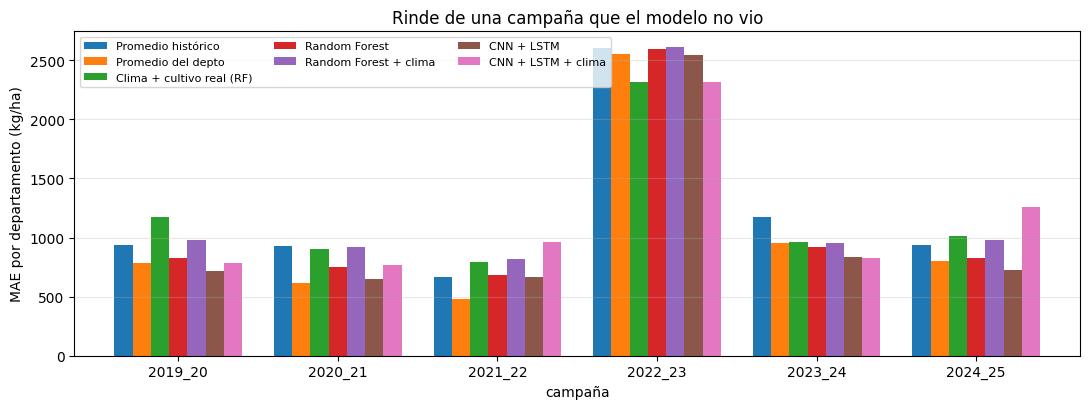

In [12]:
modelos_a = ['Referencia', 'Promedio del depto', 'Clima + cultivo real (RF)', 'Random Forest', 'Random Forest + clima', 'CNN + LSTM', 'CNN + LSTM + clima']
an = RESULT[(RESULT.esquema == 'anio') & RESULT.modelo.isin(modelos_a)].copy()
an['campaña'] = an.fold.map({k: f['nombre'] for k, f in enumerate(FOLDS['anio'])})
t = an.pivot_table(index='campaña', columns='modelo', values='MAE por depto (kg/ha)').reindex(columns=[m for m in modelos_a if m in set(an.modelo)])
t = t.rename(columns={'Referencia': 'Promedio histórico'})
print(t.round(0).to_string())
print('\nPromedio de las campañas:'); print(t.mean().round(0).to_string())

fig, ax = plt.subplots(figsize=(11, 4.2))
t.plot.bar(ax=ax, width=.8)
ax.set_ylabel('MAE por departamento (kg/ha)'); ax.set_title('Rinde de una campaña que el modelo no vio')
ax.grid(alpha=.3, axis='y'); ax.legend(fontsize=8, ncol=3)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 7.4 Pronóstico temprano: ¿cuánto se puede saber del rinde en enero?

Con datos solo hasta enero (unos 3 o 4 meses antes de la cosecha), dejando un año afuera. Es la versión más útil en la práctica: una estimación de la campaña en curso.

In [13]:
modelos_t = ['Referencia', 'Promedio del depto', 'Random Forest, hasta ene', 'Random Forest + clima, hasta ene', 'CNN + LSTM, hasta ene',
             'CNN + LSTM + clima, hasta ene', 'CNN + LSTM', 'CNN + LSTM + clima']
r = RESULT[(RESULT.esquema == 'anio') & RESULT.modelo.isin(modelos_t)]
t = r.groupby('modelo')['MAE por depto (kg/ha)'].agg(['mean', 'std']).reindex([m for m in modelos_t if m in set(r.modelo)])
t.index = [m.replace('Referencia', 'Promedio histórico') for m in t.index]
print('MAE por departamento dejando un año afuera (media ± desvío entre campañas):\n')
print(t.round(0).rename(columns={'mean': 'media', 'std': 'desvío'}).to_string())

MAE por departamento dejando un año afuera (media ± desvío entre campañas):

                                   media  desvío
Promedio histórico                1208.0   702.0
Promedio del depto                1032.0   763.0
Random Forest, hasta ene          1196.0   780.0
Random Forest + clima, hasta ene  1275.0   782.0
CNN + LSTM, hasta ene             1120.0   660.0
CNN + LSTM                        1023.0   749.0
CNN + LSTM + clima                1152.0   599.0


### 7.5 ¿Las diferencias son confiables?

Intervalo de confianza del 95 % por *bootstrap* de departamentos (2.000 remuestreos) para la diferencia de MAE por departamento. Negativo = el primer modelo tiene menos error. Si el intervalo no incluye el 0, la diferencia es confiable.

In [14]:
def por_grupo(esq, nombre):
    df = meta[['grupo', 'cultivo', 'campana', OBJ]].assign(pred=PRED[(esq, nombre)]['pr'])
    df = df[np.isfinite(df[OBJ]) & np.isfinite(df.pred)]
    return df.groupby(['grupo', 'cultivo', 'campana']).agg(real=(OBJ, 'first'), pred=('pred', 'mean')).reset_index()

def bootstrap(esq, a, b, B=2000):
    m = por_grupo(esq, a).merge(por_grupo(esq, b), on=['grupo', 'cultivo', 'campana', 'real'], suffixes=('_a', '_b'))
    m['d'] = (m.pred_a - m.real).abs() - (m.pred_b - m.real).abs()
    por_d = m.groupby('grupo').d.agg(['sum', 'size'])
    rng = np.random.default_rng(SEED)
    sims = [por_d.loc[rng.choice(por_d.index, size=len(por_d))].pipe(lambda s: s['sum'].sum() / s['size'].sum()) for _ in range(B)]
    return m.d.mean(), np.percentile(sims, 2.5), np.percentile(sims, 97.5)

comparaciones = [('CNN + LSTM + clima', 'CNN + LSTM'), ('CNN + LSTM + clima', 'Referencia'), ('CNN + LSTM', 'Referencia'),
                 ('Random Forest + clima', 'Random Forest'), ('CNN + LSTM + clima, hasta ene', 'CNN + LSTM, hasta ene'),
                 ('CNN + LSTM + clima, hasta ene', 'Referencia'),
                 ('CNN + LSTM + clima', 'Promedio del depto'), ('CNN + LSTM', 'Promedio del depto'),
                 ('Random Forest + clima', 'Promedio del depto')]
filas = []
for esq in FOLDS:
    for a, b in comparaciones:
        if (esq, a) in PRED and (esq, b) in PRED:
            d, lo, hi = bootstrap(esq, a, b)
            filas.append({'esquema': ESQUEMAS[esq], 'modelo': a, 'contra': b.replace('Referencia', 'Referencia' if esq == 'depto' else 'Promedio histórico'),
                          'Δ MAE (kg/ha)': round(d), 'IC 95 %': f'[{lo:.0f}, {hi:.0f}]',
                          '¿confiable?': 'sí, mejor' if hi < 0 else ('sí, peor' if lo > 0 else 'no')})
print(pd.DataFrame(filas).to_string(index=False))

              esquema                modelo             contra  Δ MAE (kg/ha)      IC 95 % ¿confiable?
     por departamento    CNN + LSTM + clima         CNN + LSTM            -66  [-102, -29]   sí, mejor
     por departamento    CNN + LSTM + clima         Referencia            -75  [-122, -28]   sí, mejor
     por departamento            CNN + LSTM         Referencia             -9    [-66, 45]          no
     por departamento Random Forest + clima      Random Forest           -108  [-141, -69]   sí, mejor
dejando un año afuera    CNN + LSTM + clima         CNN + LSTM            129    [86, 169]    sí, peor
dejando un año afuera    CNN + LSTM + clima Promedio histórico            -57   [-125, 12]          no
dejando un año afuera            CNN + LSTM Promedio histórico           -185 [-248, -127]   sí, mejor
dejando un año afuera Random Forest + clima      Random Forest            109    [82, 133]    sí, peor
dejando un año afuera    CNN + LSTM + clima Promedio del depto           

### 7.6 Real contra predicho, dejando un año afuera

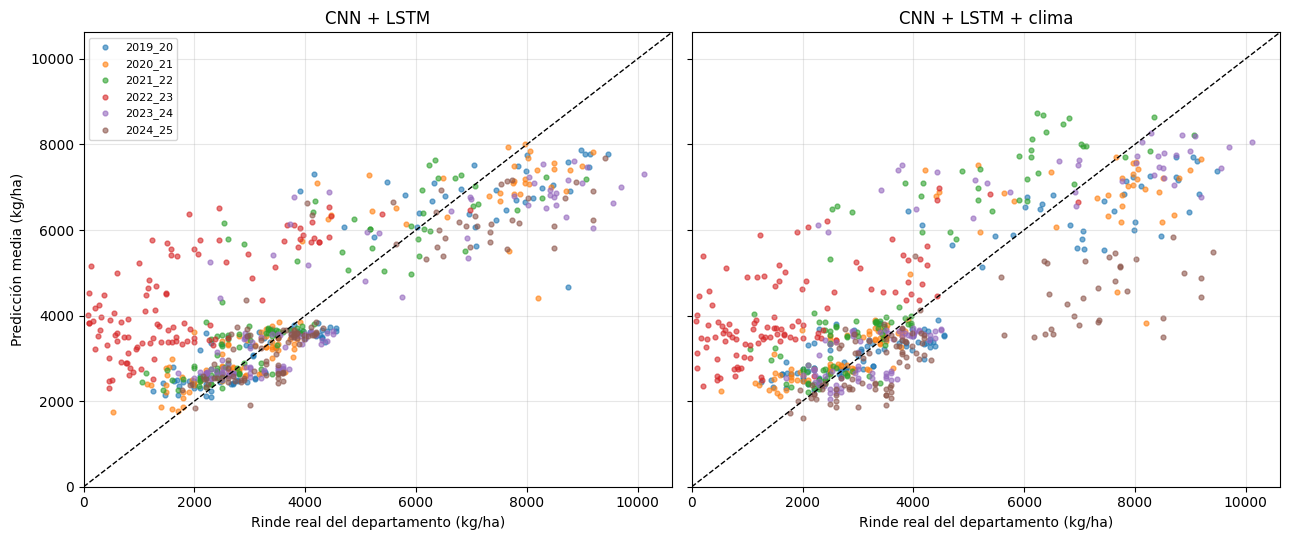

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
colores = {c: plt.cm.tab10(i) for i, c in enumerate(campanas)}
for ax, nombre in zip(axes, ['CNN + LSTM', 'CNN + LSTM + clima']):
    if ('anio', nombre) not in PRED:
        ax.set_visible(False); continue
    g = por_grupo('anio', nombre)
    for camp, s in g.groupby('campana'):
        ax.scatter(s.real, s.pred, s=12, alpha=.6, color=colores[camp], label=camp)
    lim = [0, max(g.real.max(), g.pred.max()) * 1.05]
    ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Rinde real del departamento (kg/ha)'); ax.set_title(nombre); ax.grid(alpha=.3)
axes[0].set_ylabel('Predicción media (kg/ha)'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Guardado

Se guardan las predicciones. La red con clima entrenada con todos los datos no se entrenó (`ENTRENAR_MODELO_FINAL = False`).

In [16]:
pred_df = meta[['id', 'grupo', 'campana', 'cultivo', OBJ]].copy()
for (esq, nombre), p in PRED.items():
    pred_df[f'{esq} | rinde | {nombre}'] = np.round(p['pr'], 0)
pred_df.to_csv(f'{SALIDA}/predicciones.csv', index=False)

ruta_final = f'{SALIDA}/modelo_final_cnn_lstm_clima.keras'
if ENTRENAR_MODELO_FINAL and not os.path.exists(ruta_final):
    cfg = EXPERIMENTOS['CNN + LSTM + clima']
    tr, va = particion_interna(np.arange(N), SEED)
    st = stats(tr)
    yr, yr_std, peso_r, mu, sd = preparar_rinde(tr)
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    modelo = construir_modelo(cfg['periodos'], True)
    cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)]
    modelo.fit(armar_ds(tr, yr_std, peso_r, st, True, cfg), validation_data=armar_ds(va, yr_std, peso_r, st, False, cfg),
               epochs=EPOCAS, callbacks=cb, verbose=0)
    modelo.save(ruta_final)
    json.dump({'clases': CLASES, 'canales': CANALES, 'vars_clima': VARS_CLIMA, 'periodos': cfg['periodos'], 'parche': PATCH,
               'media_canales': st[0].tolist(), 'desvio_canales': st[1].tolist(),
               'media_clima': st[2].tolist(), 'desvio_clima': st[3].tolist(), 'rinde_media': mu, 'rinde_desvio': sd,
               'como_usar': 'imagen como en el 03; clima (n, 27, 3): lluvia en mm -> log(1 + mm), tmedia y tmax en °C; '
                            'restar media_clima y dividir por desvio_clima'},
              open(f'{SALIDA}/normalizacion_modelo_final_clima.json', 'w'), indent=1)
    print('Modelo final guardado en', ruta_final)
print('Guardado en', SALIDA)

Guardado en /content/drive/MyDrive/TP_final_IA2/resultados_04
